# SRF Source Verification

    **Purpose:** verify an independent, on-demand GSTools Matérn temperature source before continuous-sensing and policy integration. This is a functional Python test, not a reconstruction-policy comparison or real-field validation.

    The current temporary domain is 97 x 64 m over 0-120 s. The previous 97 x 64 m / 900 s baseline and 30 x 30 m / 120 s run are retained unchanged. Temperature mean and sample variance use the single available aligned WELL-E run. Coordinate scales (12 m, 12 m, 180 s), Matérn smoothness 1.5, zero deterministic trend and sensor noise 0.03 degC are **provisional**, not fitted field parameters. The source uses the complete obstacle-free rectangle with a flat-scene assumption. This test does not create a Gazebo terrain or an occupancy map; previous SRF runs also used complete rectangles.

    The generator uses one fixed 1024-mode RandMeth realization in scaled coordinates (x/Lx, y/Ly, t/Lt), with a zero-nugget target covariance. Each request uses store=False. Measurement-ID-keyed noise is separate from field truth. No GP, ROS or complete 3D temperature grid is used.

In [1]:
from pathlib import Path
import csv, json
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
ROOT = Path.cwd()
RUN = ROOT / "result" / json.loads((ROOT/"result/latest.json").read_text())["run"]
summary = json.loads((RUN/"summary.json").read_text())
checks = json.loads((RUN/"checks.json").read_text())
benchmarks = json.loads((RUN/"benchmarks.json").read_text())
fine_grid = json.loads((RUN/"resolution_benchmarks.json").read_text())
config = summary["config"]
view = np.load(RUN/"visualization.npz")
print("Checks:", sum(c["passed"] for c in checks), "/", len(checks), "| Failed:", summary["failed_checks"])
print("Historical reference:", config["historical_reference"]["observations"], "observations; mean",
      round(config["mean_c"],6), "degC; sample variance", round(config["variance_c2"],6), "degC^2")
print("Single-query p95:", round(summary["query_p95_ms"],3), "ms | Initial construction:",
      round(summary["initialization_s"],3), "s")
print("Largest sampled absolute benchmark RSS:", round(summary["maximum_sampled_absolute_rss_mib"],2), "MiB")
print("Hypothetical full reference grid:", summary["dense_reference_shape"],
      "=", round(summary["dense_reference_float64_gib"],2), "GiB float64; not materialized")
assert summary["passed"] and not summary["policy_comparison_performed"]
rows = ["| Queries | Time (s) | Queries/s | Sampled peak RSS (MiB) |",
        "| ---: | ---: | ---: | ---: |"]
for b in benchmarks:
    rows.append(f'| {b["query_count"]:,} | {b["elapsed_s"]:.4f} | {b["queries_per_s"]:,.0f} | {b["sampled_peak_rss_mib"]:.2f} |')
display(Markdown(chr(10).join(rows)))
errors = [c["maximum_absolute_error_c"] for c in checks if "maximum_absolute_error_c" in c]
print("Maximum consistency error across declared equality checks:", max(errors), "degC")
print("Actual reference spacing:",summary["spatial_resolution_m"],"m /",summary["temporal_resolution_s"],"s")
print("Fine-grid shape per slice:",len(view["y"]),len(view["x"]),
      "| Direct points per slice:",summary["spatial_points_per_slice"])
grid_rows=["| Snapshot time (s) | Direct 0.1 m queries | Time (s) | Sampled peak RSS (MiB) |",
           "| ---: | ---: | ---: | ---: |"]
for b in fine_grid:
    grid_rows.append(f'| {b["time_s"]} | {b["query_count"]:,} | {b["elapsed_s"]:.3f} | {b["sampled_peak_rss_mib"]:.2f} |')
display(Markdown(chr(10).join(grid_rows)))
assert np.allclose(np.diff(view["x"]),.1) and np.allclose(np.diff(view["y"]),.1)
assert np.allclose(np.diff(view["times_s"]),.5)

Checks: 38 / 38 | Failed: []
Historical reference: 980 observations; mean 27.114476 degC; sample variance 0.040393 degC^2
Single-query p95: 0.271 ms | Initial construction: 0.066 s
Largest sampled absolute benchmark RSS: 122.62 MiB
Hypothetical full reference grid: [971, 641, 241] = 1.12 GiB float64; not materialized


| Queries | Time (s) | Queries/s | Sampled peak RSS (MiB) |
| ---: | ---: | ---: | ---: |
| 1,000 | 0.0227 | 44,025 | 108.10 |
| 10,000 | 0.2198 | 45,505 | 108.26 |
| 100,000 | 2.1960 | 45,537 | 108.27 |

Maximum consistency error across declared equality checks: 5.2735593669694936e-15 degC
Actual reference spacing: 0.1 m / 0.5 s
Fine-grid shape per slice: 641 971 | Direct points per slice: 622411


| Snapshot time (s) | Direct 0.1 m queries | Time (s) | Sampled peak RSS (MiB) |
| ---: | ---: | ---: | ---: |
| 0 | 622,411 | 7.784 | 113.11 |
| 60 | 622,411 | 7.793 | 117.86 |
| 120 | 622,411 | 7.806 | 122.62 |

## Requested spatial snapshots

    Three noise-free 2D views use a common temperature scale and 0.1 m plotting spacing. Each of the 622,411 grid points per slice was queried directly in bounded batches; no coarser-grid interpolation was used. These are selected views, not a stored 0.1 m x 0.5 s space-time volume. SRF accepts off-grid inputs; plotting spacing does not constrain sensor queries. The field is synthetic and is not the GP posterior mean.

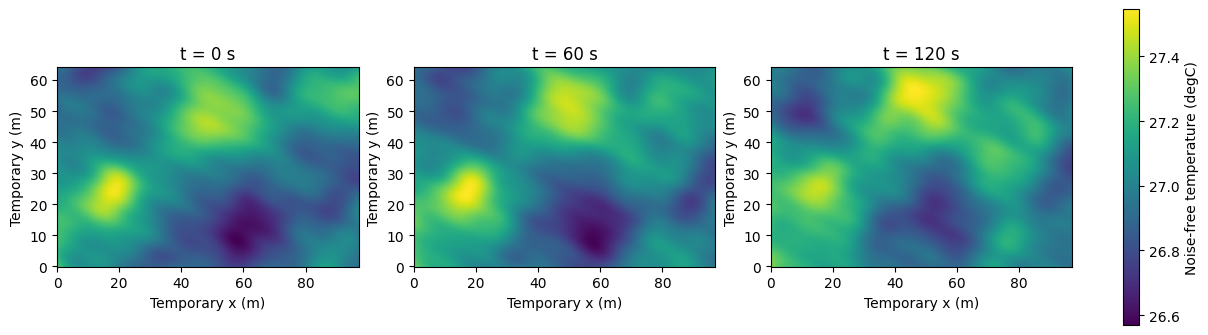

Observed slice range: [26.5696 27.5466] degC
Historical range: [26.5097 27.7538] degC
Random-field values are not clipped to historical extrema.


In [2]:
slices = view["spatial_slices"]
fig, axes = plt.subplots(1,3,figsize=(12,3.8),layout="constrained")
for ax,values,stamp in zip(axes,slices,view["snapshot_times_s"]):
    im = ax.pcolormesh(view["x"],view["y"],values,shading="auto",
                      vmin=slices.min(),vmax=slices.max(),cmap="viridis")
    ax.set(title=f"t = {stamp:g} s",xlabel="Temporary x (m)",ylabel="Temporary y (m)",aspect="equal")
fig.colorbar(im,ax=axes,label="Noise-free temperature (degC)",shrink=.85)
fig.savefig(RUN/"figures/spatial_snapshots.png",dpi=180)
plt.show()
print("Observed slice range:",np.round(summary["sampled_fixture_range_c"],4),"degC")
print("Historical range:",np.round(summary["historical_temperature_range_c"],4),"degC")
print("Random-field values are not clipped to historical extrema.")

## Temporal continuity and isolated measurement noise

    Fixed-position traces come from the same 3D field at every timestamp; the generator does not redraw independent 2D maps. These illustrative curves do not validate the selected temporal scale. Replaying the same measurement ID reproduces its noise; a new physical measurement must receive a new identity.

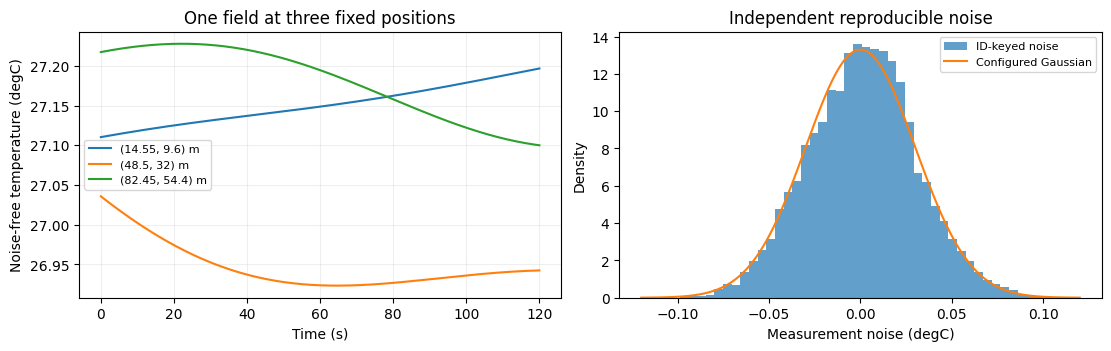

Noise audit: 5000 samples; mean = 0.000926 degC; sample std = 0.029697 degC


In [3]:
noise = np.load(RUN/"noise_samples.npy")
fig,axes = plt.subplots(1,2,figsize=(11,3.4),layout="constrained")
for point,trace in zip(view["probes_xy_m"],view["traces_c"]):
    axes[0].plot(view["times_s"],trace,label=f"({point[0]:g}, {point[1]:g}) m")
axes[0].set(xlabel="Time (s)",ylabel="Noise-free temperature (degC)",title="One field at three fixed positions")
axes[0].legend(fontsize=8);axes[0].grid(alpha=.2)
axes[1].hist(noise,bins=45,density=True,alpha=.7,label="ID-keyed noise")
xs=np.linspace(-.12,.12,300);sd=config["noise_std_c"]
axes[1].plot(xs,np.exp(-.5*(xs/sd)**2)/(sd*np.sqrt(2*np.pi)),label="Configured Gaussian")
axes[1].set(xlabel="Measurement noise (degC)",ylabel="Density",title="Independent reproducible noise")
axes[1].legend(fontsize=8)
fig.savefig(RUN/"figures/temporal_and_noise.png",dpi=180)
plt.show()
print("Noise audit:",len(noise),"samples; mean =",round(float(noise.mean()),6),
      "degC; sample std =",round(float(noise.std(ddof=1)),6),"degC")

## Bounded batch workload

    Benchmark queries are generated and evaluated in chunks of at most 1024; only aggregate statistics are retained. The 0.1 m slice workload is measured separately above; only the requested three 2D outputs are saved, alongside 0.5 s time traces. The field keeps its random-mode state and latest batch positions, not past temperature arrays.

    RSS includes native allocations and is sampled every 5 ms, so sub-sampling allocation peaks may be missed. Memory increments are measured after initialization/warm-up and must not be mistaken for total process memory. Single-query timing covers this isolated source, not a ROS deadline, sensor response, GP update or GRG runtime.

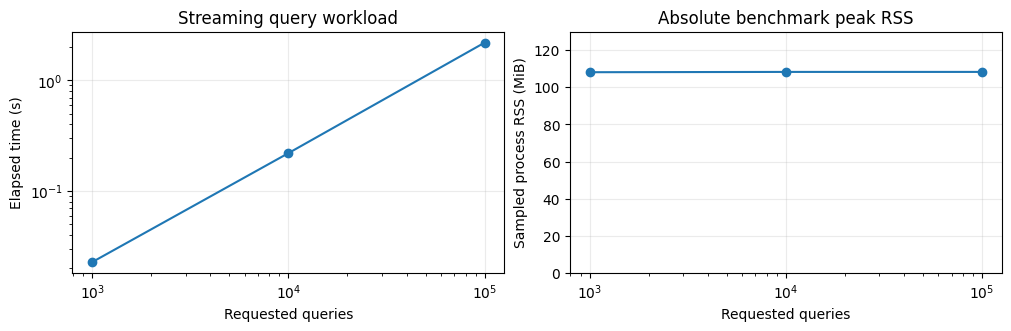

Stored field arrays: [[], [], []]
Generator-state array bytes: [40960, 40960, 40960]
Retained latest position counts: [1000, 784, 672]


In [4]:
counts=np.array([b["query_count"] for b in benchmarks])
seconds=np.array([b["elapsed_s"] for b in benchmarks])
peaks=np.array([b["sampled_peak_rss_mib"] for b in benchmarks])
fig,axes=plt.subplots(1,2,figsize=(10,3.2),layout="constrained")
axes[0].loglog(counts,seconds,"o-")
axes[0].set(xlabel="Requested queries",ylabel="Elapsed time (s)",title="Streaming query workload")
axes[1].semilogx(counts,peaks,"o-")
axes[1].set(xlabel="Requested queries",ylabel="Sampled process RSS (MiB)",title="Absolute benchmark peak RSS",ylim=(0,max(peaks)*1.2))
for ax in axes: ax.grid(alpha=.25)
fig.savefig(RUN/"figures/performance.png",dpi=180)
plt.show()
print("Stored field arrays:",[b["stored_field_names"] for b in benchmarks])
print("Generator-state array bytes:",[b["generator_array_bytes"] for b in benchmarks])
print("Retained latest position counts:",[b["retained_position_count"] for b in benchmarks])

## Retained workloads and the large flat 120 s variant

    All three runs use 0.1 m spatial / 0.5 s temporal reference spacing, identical historical mean/variance, random seeds, Matern parameters, noise and thread/batch settings. Previous result files and source snapshots remain unchanged. The common-domain check compares the latest source against the original large-domain field.

    This is a source workload comparison. The SRF source has no obstacles in any of these runs, so removing obstacles does not remove any source computation. The baseline snapshots use 0/450/900 s; both 120 s variants use 0/60/120 s. Timings are single-run wall-clock observations, not replicated statistical estimates.

In [5]:
variant_index=json.loads((ROOT/"result/variants.json").read_text())
cases=[(entry["label"],entry["run"]) for entry in variant_index["retained_runs"]]
cases.append(("Large flat / 120 s (current)",RUN.name))
records=[]
for label,name in cases:
    directory=ROOT/"result"/name
    source=json.loads((directory/"summary.json").read_text())
    frames=json.loads((directory/"resolution_benchmarks.json").read_text())
    cfg=source["config"]
    points=int(np.prod(source["dense_reference_shape"]))
    mean_frame_s=float(np.mean([row["elapsed_s"] for row in frames]))
    records.append(dict(label=label,run=name,extent_m=cfg["working_extent_m"],
                        duration_s=cfg["mission_interval_s"][1]-cfg["mission_interval_s"][0],
                        checks=source["checks"],passed=source["passed"],
                        points_per_slice=source["spatial_points_per_slice"],
                        mean_slice_s=mean_frame_s,point_query_p95_ms=source["query_p95_ms"],
                        sampled_peak_rss_mib=source["maximum_sampled_absolute_rss_mib"],
                        hypothetical_dense_queries=points,
                        hypothetical_dense_float64_gib=source["dense_reference_float64_gib"],
                        estimated_dense_source_s=mean_frame_s*source["dense_reference_shape"][2]))
lines=["| Run | Domain | Duration | Checks | Points/slice | Slice time (s) | Query P95 (ms) | Peak RSS (MiB) |",
       "| --- | --- | ---: | ---: | ---: | ---: | ---: | ---: |"]
for r in records:
    area=f'{r["extent_m"][0]} x {r["extent_m"][1]} m'
    lines.append(f'| {r["label"]} | {area} | {r["duration_s"]} s | {r["checks"]} passed | {r["points_per_slice"]:,} | {r["mean_slice_s"]:.3f} | {r["point_query_p95_ms"]:.3f} | {r["sampled_peak_rss_mib"]:.2f} |')
display(Markdown(chr(10).join(lines)))
for r in records:
    print(r["label"],": hypothetical full-domain/all-time source cost",
          round(r["estimated_dense_source_s"]/60,2),"min;",
          format(r["hypothetical_dense_queries"],","),"queries;",
          round(r["hypothetical_dense_float64_gib"],3),"GiB for temperature float64 values alone.",
          "Linear estimate only; the complete volume was NOT executed or allocated.")
shared=next(c for c in checks if c["name"]=="same_field_on_common_baseline_domain")
print("Same field on shared physical inputs:",shared)
assert shared["passed"] and all(r["passed"] for r in records)
current=records[-1]
print("At 1 Hz, a 120 s moving sensor needs approximately 120 individual source queries,",
      "not 241 complete 0.1 m maps. Query P95 =",round(current["point_query_p95_ms"],3),"ms.",
      "This excludes ROS, GP, scoring and GRG overhead.")
report_comparison=dict(current_run=RUN.name,retained_files_preserved=True,
                       common_domain_field_check=shared,runs=records,
                       dense_cost_estimate_only=True,complete_volume_executed=False,
                       previous_srf_runs_also_obstacle_free=True)
(RUN/"baseline_comparison.json").write_text(json.dumps(report_comparison,indent=2)+chr(10))

| Run | Domain | Duration | Checks | Points/slice | Slice time (s) | Query P95 (ms) | Peak RSS (MiB) |
| --- | --- | ---: | ---: | ---: | ---: | ---: | ---: |
| Large / 900 s baseline | 97 x 64 m | 900 s | 37 passed | 622,411 | 7.885 | 0.281 | 122.76 |
| Small / 120 s | 30 x 30 m | 120 s | 38 passed | 90,601 | 1.025 | 0.270 | 109.89 |
| Large flat / 120 s (current) | 97 x 64 m | 120 s | 38 passed | 622,411 | 7.795 | 0.271 | 122.62 |

Large / 900 s baseline : hypothetical full-domain/all-time source cost 236.67 min; 1,120,962,211 queries; 8.352 GiB for temperature float64 values alone. Linear estimate only; the complete volume was NOT executed or allocated.
Small / 120 s : hypothetical full-domain/all-time source cost 4.12 min; 21,834,841 queries; 0.163 GiB for temperature float64 values alone. Linear estimate only; the complete volume was NOT executed or allocated.
Large flat / 120 s (current) : hypothetical full-domain/all-time source cost 31.31 min; 150,001,051 queries; 1.118 GiB for temperature float64 values alone. Linear estimate only; the complete volume was NOT executed or allocated.
Same field on shared physical inputs: {'name': 'same_field_on_common_baseline_domain', 'passed': True, 'maximum_absolute_error_c': 0.0}
At 1 Hz, a 120 s moving sensor needs approximately 120 individual source queries, not 241 complete 0.1 m maps. Query P95 = 0.271 ms. This excludes ROS, GP, scoring and GRG overhead.


1987

## Computational implication

    Extending the spatial domain increases complete-map work; shortening the allowed time interval reduces the number of hypothetical time slices, not the work of one point query or one complete spatial slice. On-demand sensor queries need no grid snapping and no precomputed full volume. A 1 Hz sensor does not require rebuilding the entire temperature map every second.

    The dense source estimate multiplies the mean of three directly measured slice times by the number of 0.5 s timestamps. It excludes downstream GP evaluation, policy scoring, rendering, file output and ROS execution; it is not an end-to-end mission benchmark.

## Conclusion and remaining scope

    **Passed:** fixed-realization repeat/order/batch/restart consistency, explicit space/time scaling, independent stable-ID noise, strict input handling, bounded stored state and the predeclared isolated-query/memory checks. All detailed checks are in checks.json; environment, source hashes and source-data provenance are in manifest.json.

    These checks support using this source for **functional** moving-sensor tests; they do not validate full-system mission timing. Real-site map registration/masking, multi-run covariance/trend calibration, sensor response/noise identification, finite-mode approximation adequacy, ROS integration and policy performance remain pending. One random field and one benchmark do not establish statistical reliability or real-world fidelity.

    Implementation uses the documented [GSTools SRF interface](https://geostat-framework.readthedocs.io/projects/gstools/en/stable/api/gstools.field.SRF.html), [Matérn model](https://geostat-framework.readthedocs.io/projects/gstools/en/stable/api/gstools.covmodel.Matern.html), and [RandMeth finite-mode generator](https://geostat-framework.readthedocs.io/projects/gstools/en/stable/api/gstools.field.generator.RandMeth.html).